## Data Understanding phase 

### Problem Statement
-------------------------
> "Car Buying Advisor" — helps a prospective buyer decide between luxury car brands/models using real owner review data, with grounded, cited answers instead of generic marketing claims.

Example questions it should answer: 
- "What do BMW owners complain about most after 3 years?",
- "Compare Audi vs Lexus on ride comfort",
- "Is the Audi Q5 reliable long-term based on real reviews?"
  
This is a decision-support tool, not a generic chatbot 

In [3]:
import pandas as pd
df = pd.read_csv("reviews/38000_review.csv",index_col=0)

#First 5 rows
df.head(5)

,Rating,car_year,brand_name,date,review
0,5.0,2018,Audi,2018-07-11,BEST ALL AROUND PURPOSE CROSSOVER SUV I have n...
1,5.0,2018,Audi,2018-06-24,Best car This is a wonderful car. The technol...
2,5.0,2018,Audi,2018-05-02,Great Buy Do your home work
3,5.0,2018,Audi,2017-12-07,Fun Car Great ride. Loaded with technology. St...
4,5.0,2018,Audi,2017-10-25,Best luxury SUV w/ perfect comfort/sport balan...


In [4]:
#Last 5 rows
df.tail(5)

,Rating,car_year,brand_name,date,review
31933,4.75,2015,Mercedes-Benz,2015-06-04,One week in but I love it. I just got the car...
31934,4.00,2015,Mercedes-Benz,2015-05-19,A delightful car I have been driving the GLA25...
31935,3.00,2015,Mercedes-Benz,2015-02-21,This car is amazing but visibility is poor We ...
31936,2.75,2015,Mercedes-Benz,2015-01-20,Steering Wheel Module When I first bought this...
31937,4.50,2015,Mercedes-Benz,2014-10-06,Fun crossover/hatchback but not an SUV. I've h...


In [5]:
#Number of rows and columns
#We get to find that there almost 32,000 records 
df.shape

(31938, 5)

In [6]:
#We see that there are 5 column with the names given below.
df.columns

Index(['Rating', 'car_year', 'brand_name', 'date', 'review'], dtype='object')

In [7]:
df.dtypes

Rating        float64
car_year        int64
brand_name     object
date           object
review         object
dtype: object

In [8]:
#Describe method is used to get major stastical values like mean, min_value, max_value
df.describe(include='all')

,Rating,car_year,brand_name,date,review
count,31938.000000,31938.000000,31938,31938,31938
unique,NaN,NaN,5,5706,31875
top,NaN,NaN,BMW,2004-07-10,Great car
freq,NaN,NaN,8060,71,5
mean,4.476331,2005.959296,NaN,NaN,NaN
std,0.783148,5.101718,NaN,NaN,NaN
min,1.000000,1997.000000,NaN,NaN,NaN
25%,4.375000,2002.000000,NaN,NaN,NaN
50%,4.750000,2005.000000,NaN,NaN,NaN
75%,5.000000,2009.000000,NaN,NaN,NaN


In [9]:
df['Rating'].describe()

count    31938.000000
mean         4.476331
std          0.783148
min          1.000000
25%          4.375000
50%          4.750000
75%          5.000000
max          5.000000
Name: Rating, dtype: float64

In [10]:
df['brand_name'].value_counts()

brand_name
BMW              8060
Mercedes-Benz    7375
Lexus            6153
Audi             6043
INFINITI         4307
Name: count, dtype: int64

In [11]:
df['brand_name'].nunique()

5

In [12]:
df['brand_name'].value_counts(normalize=True) * 100

brand_name
BMW              25.236396
Mercedes-Benz    23.091615
Lexus            19.265452
Audi             18.921035
INFINITI         13.485503
Name: proportion, dtype: float64

## Investigating the rating column

In [13]:
df['Rating'].isna().sum()

np.int64(0)

In [14]:
import matplotlib.pyplot as plt

# Create rating intervals
df['Rating_Bin'] = pd.cut(
    df['Rating'],
    bins=range(0, int(df['Rating'].max()) + 2),
    right=False
)

# Count each interval
rating_counts = df['Rating_Bin'].value_counts().sort_index()

print(rating_counts)

Rating_Bin
[0, 1)        0
[1, 2)      546
[2, 3)     1205
[3, 4)     3043
[4, 5)    17363
[5, 6)     9781
Name: count, dtype: int64


In [15]:
#Average rating of each brand
df.groupby('brand_name')['Rating'].mean()

brand_name
Audi             4.464515
BMW              4.474364
INFINITI         4.481643
Lexus            4.568473
Mercedes-Benz    4.408186
Name: Rating, dtype: float64

## Basic EDA

In [16]:
#There are no null values
summary = pd.DataFrame(
    {
        "null_values": df.isnull().sum(),
        "unique_values": df.nunique()
    }
)

print(summary)

            null_values  unique_values
Rating                0            150
car_year              0             22
brand_name            0              5
date                  0           5706
review                0          31875
Rating_Bin            0              5


## Inspect the date column

In [17]:
df['date'] = pd.to_datetime(df['date'],errors='coerce')
print(df['date'].dtype)

datetime64[ns]


In [18]:
df['date'].min()

Timestamp('2002-02-19 00:00:00')

In [43]:
df['date'].max()

Timestamp('2018-09-19 00:00:00')

## Inspect the review column without NLP

In [19]:
df['review'].isna().sum()

np.int64(0)

In [21]:
df['review_length'] = df['review'].str.len()
df[['review','review_length']].head(10)

,review,review_length
0,BEST ALL AROUND PURPOSE CROSSOVER SUV I have n...,1004
1,Best car This is a wonderful car. The technol...,160
2,Great Buy Do your home work,27
3,Fun Car Great ride. Loaded with technology. St...,71
4,Best luxury SUV w/ perfect comfort/sport balan...,1570
5,Great car!!! Still new. Everything seems worki...,149
6,Exceptionally balanced vehicle Ive owned alot ...,1291
7,"A rare find! I have owned a 2006 BMW X5, 4.4V8...",1920
8,What a Cayenne Turbo driver thinks of this car...,1520
9,"Hold On Punch the gas and hold on, this baby w...",213


In [49]:
df['review_length'].describe()

count    31938.000000
mean       495.137297
std        432.444951
min          3.000000
25%        247.000000
50%        448.000000
75%        672.000000
max       5045.000000
Name: review_length, dtype: float64

In [22]:
df[df['review_length']<20][['brand_name','Rating','review']]

,brand_name,Rating,review
126,Audi,5.0,Audi Q5 2.0
248,Audi,5.0,Great car
260,Audi,5.0,Love my Audi!
455,Audi,5.0,Power Awesome car.
715,Audi,5.0,All road fan
...,...,...,...
31774,Mercedes-Benz,5.0,get what you pay
31784,Mercedes-Benz,5.0,Love it
31863,Mercedes-Benz,5.0,None None
31892,Mercedes-Benz,5.0,Return MB buyer


In [23]:
df.groupby("brand_name")['Rating'].agg(['count','min','max','mean','median'])

,count,min,max,mean,median
brand_name,,,,,
Audi,6043,1.0,5.0,4.464515,4.750
BMW,8060,1.0,5.0,4.474364,4.750
INFINITI,4307,1.0,5.0,4.481643,4.750
Lexus,6153,1.0,5.0,4.568473,4.875
Mercedes-Benz,7375,1.0,5.0,4.408186,4.750


## Rating Column Analysis

In [24]:
#Duplicate reviews and columns check
print(df.duplicated().sum())

47


In [25]:
print(df['review'].duplicated().sum())

63


In [26]:
print(df['Rating'].describe())
print("\n")


print("Unique rating values:",df['Rating'].nunique())

count    31938.000000
mean         4.476331
std          0.783148
min          1.000000
25%          4.375000
50%          4.750000
75%          5.000000
max          5.000000
Name: Rating, dtype: float64


Unique rating values: 150


count    31938.000000
mean      2005.959296
std          5.101718
min       1997.000000
25%       2002.000000
50%       2005.000000
75%       2009.000000
max       2018.000000
Name: car_year, dtype: float64




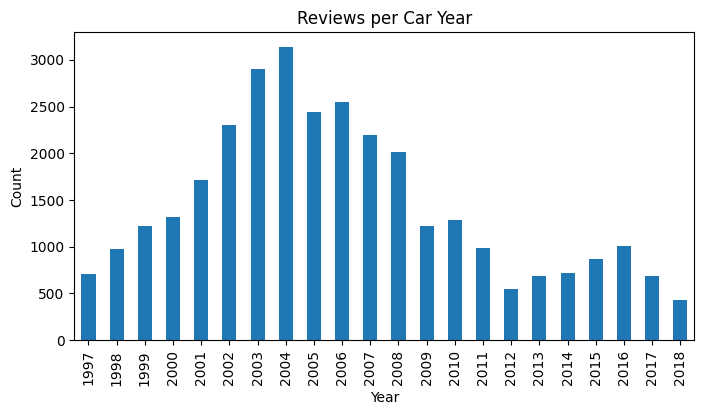

In [27]:
print(df['car_year'].describe())

print('\n')

plt.figure(figsize=(8,4))
df['car_year'].value_counts().sort_index().plot(kind='bar')
plt.title("Reviews per Car Year")
plt.xlabel("Year")
plt.ylabel("Count")
plt.show()

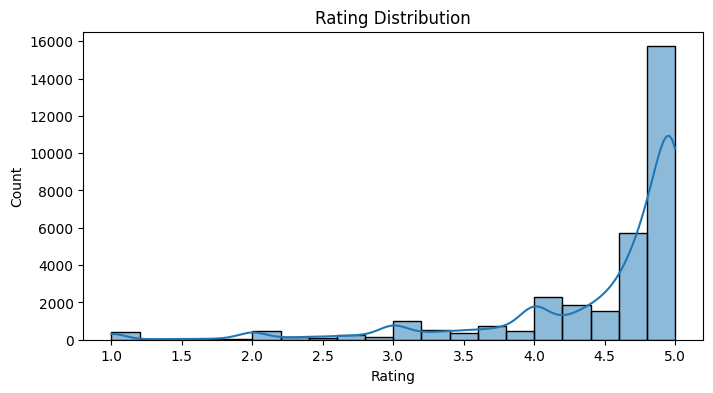

In [28]:
import seaborn as sns

#Rating distribution
plt.figure(figsize=(8,4))
sns.histplot(df['Rating'],bins=20,kde=True)
plt.title("Rating Distribution")
plt.show()

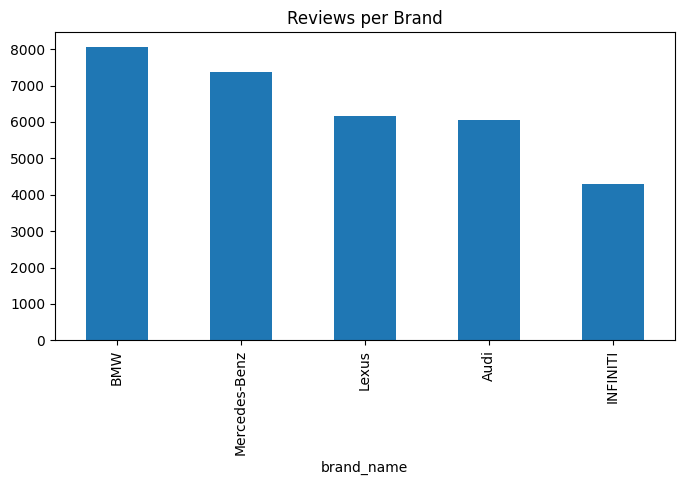

In [29]:
import seaborn as sns

plt.figure(figsize=(8,4))
df['brand_name'].value_counts().plot(kind='bar')
plt.title("Reviews per Brand")
plt.show()

In [30]:
short_reviews = df[df['review_length']<20]
print("Short Reviews count: ", len(short_reviews))

df['is_short_review'] = df['review_length']<20

Short Reviews count:  182


In [31]:
# IQR method
Q1 = df['review_length'].quantile(0.25)
Q3 = df['review_length'].quantile(0.75)
IQR = Q3 - Q1

upper = Q3 + 1.5*IQR
lower = Q1 - 1.5*IQR

print("Upper bound length:", upper)
print("Outlier count:", (df['review_length'] > upper).sum())

print("Lower bound length:", lower)
print("Outlier count:", (df['review_length'] < lower).sum())

Upper bound length: 1309.5
Outlier count: 1031
Lower bound length: -390.5
Outlier count: 0


## Correlation plots

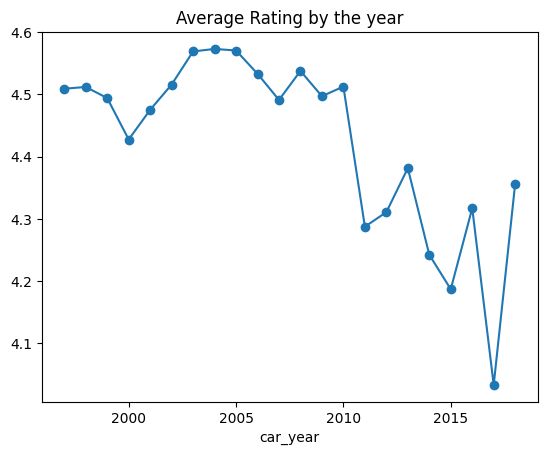

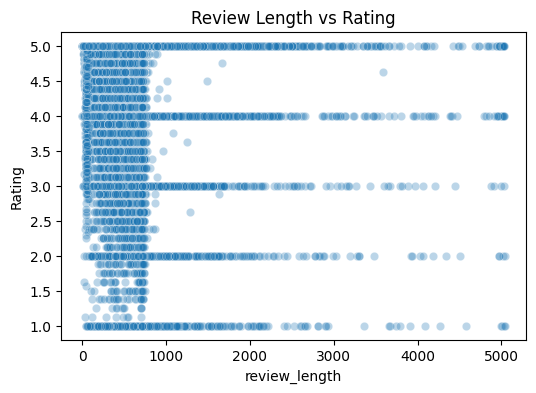

                 Rating  review_length  car_year
Rating         1.000000      -0.194212 -0.100746
review_length -0.194212       1.000000  0.269537
car_year      -0.100746       0.269537  1.000000


In [32]:
df.groupby('car_year')['Rating'].mean().plot(kind='line',marker='o')
plt.title("Average Rating by the year")
plt.show()

# Rating vs review_length
plt.figure(figsize=(6,4))
sns.scatterplot(x='review_length', y='Rating', data=df, alpha=0.3)
plt.title("Review Length vs Rating")
plt.show()

print(df[['Rating','review_length','car_year']].corr())


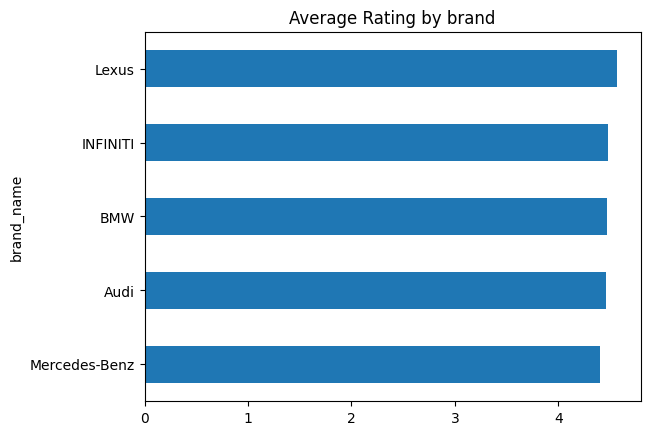

In [33]:
df.groupby("brand_name")['Rating'].mean().sort_values().plot(kind='barh')
plt.title("Average Rating by brand")
plt.show()

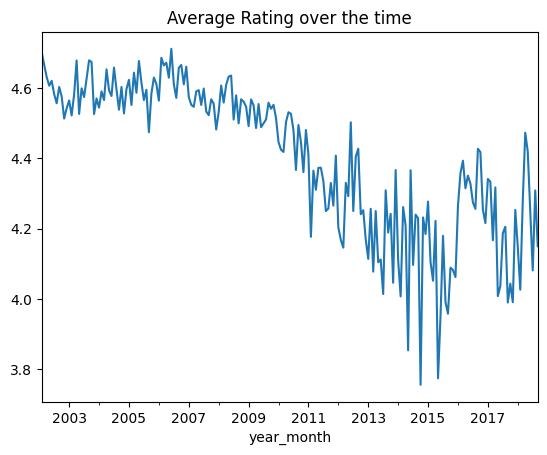

In [34]:
#Rating over the time

df['date']= pd.to_datetime(df['date'],errors='coerce')
df['year_month'] = df['date'].dt.to_period("M")

df.groupby("year_month")["Rating"].mean().plot(kind='line')
plt.title("Average Rating over the time")
plt.show()

In [36]:
#Capping the extreme review lengths instead of dropping them 
#Implementing capping and inspecting the reviews before capping them

#find the 99th percentile
cap = df['review_length'].quantile(0.99)
print("99th Percentile:", cap)

# 2. Get reviews above the 99th percentile
extreme_reviews = df[df['review_length'] > cap]
extreme_reviews[['review_length', 'review']].head(5)


#Values seem legitamate so keeping them 

99th Percentile: 2253.150000000005


,review_length,review
13,5004,"What a dissapointment If interested, you may w..."
37,2727,"Very Sporty, great quality but This 2012 car (..."
64,2573,I dont like a car that thinks its smarter then...
98,2874,Comfort Seats are “Discomfort Seats” Had a loa...
342,4184,Help is on the way This is my third update on ...


In [92]:
#Duplicate Analysis
print("Duplicate rows:", df.duplicated().sum())

duplicates = (
    df[df.duplicated(keep=False)]
    .sort_values(by=df.columns.tolist())
)

print(duplicates)

#Duplicates existing so dropping and keeping a copy
df = df.drop_duplicates()

Duplicate rows: 47
       Rating  car_year     brand_name       date  \
28287   2.875      1998  Mercedes-Benz 2002-10-14   
28288   2.875      1998  Mercedes-Benz 2002-10-14   
29      3.000      2012           Audi 2018-06-03   
30      3.000      2012           Audi 2018-06-03   
2915    3.000      2017           Audi 2016-10-08   
...       ...       ...            ...        ...   
30212   5.000      2016  Mercedes-Benz 2016-08-07   
16421   5.000      2017       INFINITI 2017-02-25   
16422   5.000      2017       INFINITI 2017-02-25   
10716   5.000      2018          Lexus 2018-05-22   
10717   5.000      2018          Lexus 2018-05-22   

                                                  review Rating_Bin  \
28287  Problems! I bought the vehicle used with 30K \...     [2, 3)   
28288  Problems! I bought the vehicle used with 30K \...     [2, 3)   
29     Turbo Lag spoils the fun A really nice size li...     [3, 4)   
30     Turbo Lag spoils the fun A really nice size li...    

In [93]:
print("Duplicates after cleaning:", df.duplicated().sum())
print("Rows remaining:", len(df))

Duplicates after cleaning: 0
Rows remaining: 31891


In [ ]:
import os
import pandas as pd

os.makedirs('data', exist_ok=True)

# 1. Export Brand Stats
brand_stats = df.groupby('brand_name').agg(
    review_count=('Rating', 'count'),
    avg_rating=('Rating', 'mean'),
    median_rating=('Rating', 'median'),
    rating_std=('Rating', 'std'),
    avg_car_year=('car_year', 'mean')
).reset_index()
brand_stats.to_csv('data/brand_stats.csv', index=False)

# 2. Export Rating Trends (Aggregate + Brand-level if available)
if 'brand_name' in df.columns:
    rating_trends = df.groupby(['car_year', 'brand_name']).agg(
        avg_rating=('Rating', 'mean'),
        review_count=('Rating', 'count')
    ).reset_index()
    rating_trends.to_csv('data/rating_trends.csv', index=False)
else:
    rating_trends_agg = df.groupby('car_year').agg(
        avg_rating=('Rating', 'mean'),
        review_count=('Rating', 'count')
    ).reset_index()
    rating_trends_agg.to_csv('data/rating_trends.csv', index=False)

# Exploratory Data Analysis — Car Reviews

## 1. Objective

The objective of this EDA is to understand the structure, quality, distribution, and basic patterns in the car review dataset before moving into deeper analysis.

The dataset is intended to support a **Car Buying Advisor** that can provide data-driven comparisons and insights about five luxury car brands based on owner reviews.

The EDA focuses on:

* Understanding the dataset structure
* Checking data quality
* Understanding brand-wise review distribution
* Analysing ratings
* Understanding car-year distribution
* Inspecting review length
* Identifying duplicate records
* Identifying initial business-level insights

NLP-based analysis is intentionally outside the scope of this EDA.

---

## 2. Dataset Overview

The dataset contains **31,938 reviews** and **5 columns**:

| Column       | Description                            |
| ------------ | -------------------------------------- |
| `Rating`     | Numerical rating given by the reviewer |
| `car_year`   | Model year of the reviewed car         |
| `brand_name` | Car brand                              |
| `date`       | Review date                            |
| `review`     | Written owner review                   |

The five brands present in the dataset are:

* Audi
* BMW
* INFINITI
* Lexus
* Mercedes-Benz

The dataset contains no missing values across these original columns.

---

## 3. Data Types and Basic Statistics

The initial data inspection showed:

* `Rating` → `float64`
* `car_year` → `int64`
* `brand_name` → `object`
* `date` → initially `object`
* `review` → `object`

The `date` column was subsequently converted to `datetime64[ns]` for time-based analysis.

Overall rating statistics:

* Mean rating: **4.476**
* Median rating: **4.75**
* Minimum rating: **1.0**
* Maximum rating: **5.0**
* Standard deviation: **0.783**

The ratings are therefore strongly concentrated toward the higher end of the scale.

---

## 4. Brand Distribution

The number of reviews varies across the five brands:

| Brand         | Reviews |  Share |
| ------------- | ------: | -----: |
| BMW           |   8,060 | 25.24% |
| Mercedes-Benz |   7,375 | 23.09% |
| Lexus         |   6,153 | 19.27% |
| Audi          |   6,043 | 18.92% |
| INFINITI      |   4,307 | 13.49% |

BMW has the largest representation, while INFINITI has the smallest.

### Insight

The dataset is **not perfectly balanced across brands**.

BMW accounts for approximately one-quarter of all reviews, whereas INFINITI accounts for approximately 13.5%.

This is important for future brand comparisons because differences in review volume should be considered when interpreting aggregate statistics.

---

## 5. Rating Distribution

The rating analysis shows a strong concentration of high ratings.

The rating intervals produced the following distribution:

| Rating interval | Reviews |
| --------------- | ------: |
| 1–<2            |     546 |
| 2–<3            |   1,205 |
| 3–<4            |   3,043 |
| 4–<5            |  17,363 |
| 5–<6            |   9,781 |

Therefore, the vast majority of reviews are concentrated between **4 and 5 stars**.

### Insight

The dataset has a clear **positive-rating skew**.

This means that later analyses should not simply assume that the average rating is sufficient to describe customer perception. The distribution itself is important.

For example, two brands could have similar average ratings while having different proportions of 3-star, 4-star, and 5-star reviews.

---

## 6. Brand-wise Rating Analysis

The average and median ratings were calculated for each brand:

| Brand         | Reviews | Mean Rating |    Median |
| ------------- | ------: | ----------: | --------: |
| Audi          |   6,043 |       4.465 |     4.750 |
| BMW           |   8,060 |       4.474 |     4.750 |
| INFINITI      |   4,307 |       4.482 |     4.750 |
| Lexus         |   6,153 |   **4.568** | **4.875** |
| Mercedes-Benz |   7,375 |       4.408 |     4.750 |

### Insight

**Lexus has the highest average rating and the highest median rating** among the five brands.

Mercedes-Benz has the lowest average rating.

However, the difference between the brands is relatively small. Therefore, it would be inappropriate to conclude from this EDA alone that Lexus is definitively the "best" brand.

The next stage of analysis should investigate the rating distributions and other factors before making such a conclusion.

---

## 7. Car Year Analysis

The `car_year` variable contains **22 unique model years**.

Statistics:

* Minimum: **1997**
* Maximum: **2018**
* Mean: **2005.96**
* Median: **2005**
* Standard deviation: **5.10**

The notebook also visualised the number of reviews available for each car year.

### Insight

The dataset covers a relatively broad range of vehicle model years, from 1997 through 2018.

This creates an opportunity for future analysis such as:

* Rating vs. car year
* Brand performance across model years
* Whether newer/older vehicles receive different ratings

However, the current EDA does not establish any relationship between car year and rating.

---

## 8. Review Data Quality

The review column contains no null values.

There are:

* **31,875 unique reviews**
* **63 duplicated review values**

The shortest-review investigation identified **182 reviews with fewer than 20 characters**. Examples include short reviews such as "Great car", "Love my Audi!", and similar brief comments.

### Insight

Not every short review should automatically be removed.

A short review such as "Great car" is still a legitimate customer opinion.

Therefore, review length should be treated as a **data-quality characteristic**, rather than automatically defining short reviews as invalid.

---

## 9. Review Length

A `review_length` feature was created using the character length of each review.

Statistics:

* Mean: **495 characters**
* Median: **448 characters**
* Minimum: **3 characters**
* Maximum: **5,045 characters**
* 75th percentile: **672 characters**

### Insight

Review length varies considerably.

Most reviews are moderate in length, but there are also very long reviews.

The presence of long reviews does not necessarily indicate bad data. They should be inspected before deciding whether any transformation, such as capping, is appropriate.

This is particularly important because removing legitimate long reviews could introduce bias.

---

## 10. Duplicate Analysis

Two types of duplication were investigated.

### Complete-row duplicates

There are **47 completely duplicated rows**.

### Duplicate review text

There are **63 duplicated review values**.

### Insight

Duplicate review text and duplicate rows are not necessarily the same problem.

A repeated review may represent:

* An actual duplicate record
* The same text associated with different metadata
* A data collection artifact

Therefore, duplicates should be inspected before removal rather than blindly dropping them.

---

## 11. Date Analysis

The `date` column was converted to a proper datetime type.

The dataset covers reviews from:

**19 February 2002 → 19 September 2018**

### Insight

The dataset has a meaningful temporal dimension.

This can support future analysis such as:

* Rating trends over time
* Brand rating trends
* Changes in review volume
* Car-year vs. review-date analysis

These relationships have not yet been established by the current EDA.

---

# Key Findings

The EDA has established the following:

1. The dataset contains **31,938 car reviews across five brands**.

2. **BMW has the largest number of reviews**, while INFINITI has the smallest representation.

3. The dataset is **not perfectly balanced by brand**, so review volume should be considered when comparing brands.

4. Ratings are strongly concentrated toward the upper end of the scale, with most reviews falling between **4 and 5**.

5. **Lexus has the highest average rating (4.568) and median rating (4.875)**.

6. **Mercedes-Benz has the lowest average rating (4.408)** among the five brands.

7. The dataset contains car years from **1997 to 2018**, providing a useful dimension for future analysis.

8. There are **47 complete duplicate rows** and **63 duplicated review values**, which should be investigated before final cleaning.

9. Review lengths vary substantially, from **3 to 5,045 characters**.

10. There are **182 very short reviews**, but short reviews are not automatically invalid.

11. The review data contains **no missing values** in the original dataset columns.

12. Reviews span the period from **2002 to 2018**, providing a temporal dimension for further analysis.

---

# Business Value Identified So Far

The EDA already gives us the foundation for a **Car Buying Advisor**.

The next question should no longer be:

> "What does the dataset contain?"

We now move toward:

> **"What useful questions can this dataset answer for someone trying to choose between these brands?"**

For example:

* Which brand has the highest customer rating?
* How different are the rating distributions between brands?
* Does customer rating change with vehicle age/model year?
* Does a particular brand perform better for older vehicles?
* How does customer perception change over time?
* Which brands have unusually high proportions of low-rated reviews?

These analyses will produce the **business-level metrics and insights that we can eventually expose through the MCP server**.

NLP can then be added later to answer the qualitative question:

> **"Why are customers rating a particular brand this way?"**
